<a href="https://colab.research.google.com/github/leejsya/MLProgramming/blob/main/week6/DL_Abalone_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### Library & Module Import

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Preprocessing

In [ ]:
df = pd.read_csv("./Data/abalone.csv")
df.head()

,id,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [ ]:
# 결측값 확인
df.isna().sum()

id                0
Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
dtype: int64

In [ ]:
df = df[(df['Height'] > 0) & (df['Height'] < 0.5)]

Text(0, 0.5, 'count')

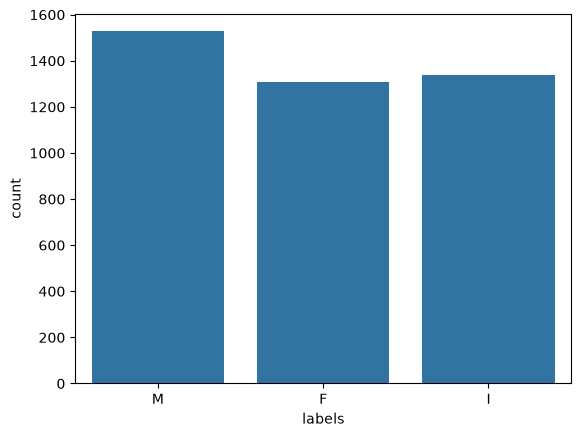

In [ ]:
# 클래스별 데이터 분포 확인
sns.countplot(data=df, x='Sex')
plt.xlabel('labels')
plt.ylabel('count')

In [ ]:
le = LabelEncoder()
df['Sex'] = le.fit_transform(df['Sex'])

# 클래스가 어떻게 인코딩됐는지 확인
for i, name in enumerate(le.classes_):
    print(name, i)

F 0
I 1
M 2


In [ ]:
# input, target 설정
X = df.drop(['Sex', 'id'], axis=1)
y = df['Sex']

print(X.head())
print("\n")
print(y.head())

   Length  Diameter  Height  Whole_weight  Shucked_weight  Viscera_weight  \
0   0.455     0.365   0.095        0.5140          0.2245          0.1010   
1   0.350     0.265   0.090        0.2255          0.0995          0.0485   
2   0.530     0.420   0.135        0.6770          0.2565          0.1415   
3   0.440     0.365   0.125        0.5160          0.2155          0.1140   
4   0.330     0.255   0.080        0.2050          0.0895          0.0395   

   Shell_weight  Rings  
0         0.150     15  
1         0.070      7  
2         0.210      9  
3         0.155     10  
4         0.055      7  


0    2
1    2
2    0
3    2
4    1
Name: Sex, dtype: int64


In [ ]:
len(X.columns)

8

In [ ]:
# 시드 고정
seed = 42

# 6 : 2 : 2로 train/val/test 분할
X_temp, X_test, y_temp, y_test = train_test_split(X, y,
                                                test_size=0.2,
                                                stratify=y,
                                                random_state=seed)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp,
                                                test_size=0.25,
                                                stratify=y_temp,
                                                random_state=seed)


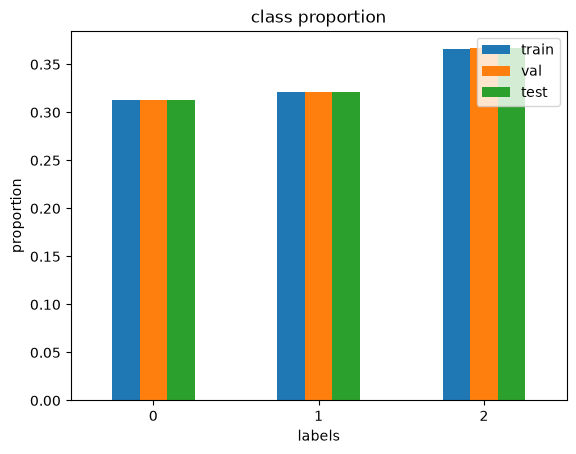

In [ ]:
# train/val/test가 잘 분할되었는지 비율 확인
train_prop = y_train.value_counts(normalize=True).sort_index()
val_prop = y_val.value_counts(normalize=True).sort_index()
test_prop = y_test.value_counts(normalize=True).sort_index()

prop_df = pd.DataFrame(
    {
        'train': train_prop,
        'val': val_prop,
        'test': test_prop
    }
)
prop_df.plot.bar(rot=0)
plt.xlabel('labels')
plt.ylabel('proportion')
plt.title('class proportion')
plt.show()

In [ ]:
# Standardization
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

#### Dataset

In [ ]:
class AbaloneDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y.to_numpy()
    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        X_tensor = torch.tensor(self.X[index], dtype=torch.float32)
        y_tensor = torch.tensor(self.y[index], dtype=torch.long)

        return X_tensor, y_tensor


train_dataset = AbaloneDataset(X_train_scaled, y_train)
val_dataset = AbaloneDataset(X_val_scaled, y_val)
test_dataset = AbaloneDataset(X_test_scaled, y_test)

#### DataLoader

In [ ]:
torch.manual_seed(seed)
train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=32,
    shuffle=True,
    drop_last=True
)
val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=32,
)
test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=32,
)

#### Model

In [ ]:
class AbaloneModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(8, 32)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 8)
        self.fc4 = nn.Linear(8, 3)
        self.dropout = nn.Dropout()
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3(x)
        x = self.relu(x)
        # x = self.dropout(x)
        x = self.fc4(x)
        return x

#### Setup

In [ ]:
model = AbaloneModel()
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
model.to(device)
print(device)

mps


#### Validation & Test function

In [ ]:
def evaluate(dataloader, model, loss_fn):
    model.eval()
    # loss값을 저장하는 리스트
    losses = []
    # 모델이 맞춘 개수
    correct = 0
    # 총 개수
    total = 0
    # 모든 예측값 리스트
    all_preds = []
    # 모든 라벨값 리스트
    all_labels = []
    with torch.no_grad():
        for batch in dataloader:
            inputs, labels = batch[0].to(device), batch[1].to(device)
            preds = model(inputs)
            loss = loss_fn(preds, labels)
            # loss 벡터를 losses 리스트에 넣음.
            losses.append(loss.item())
            # 확률이 가장 높은 클래스를 예측값으로
            pred_labels = torch.argmax(preds, dim=1)
            # 예측값과 라벨값이 같은 횟수를 더하여 저장.
            correct += (pred_labels == labels).sum().item()
            # 총 예측값 개수를 더하여 저장
            total += len(preds)

            # 각 배치의 예측값 텐서를 리스트에 저장
            all_preds.append(pred_labels.cpu())
            # 각 배치의 라벨값 텐서를 리스트에 저장
            all_labels.append(labels.cpu())

    # 각 배치의 예측값 텐서들을 행으로 이어붙임.
    all_preds = torch.cat(all_preds)
    # 각 배치의 라벨값 텐서들을 행으로 이어붙임.
    all_labels = torch.cat(all_labels)

    avg_loss = sum(losses) / len(losses)
    acc = correct / total

    return avg_loss, acc, all_preds, all_labels

#### Train Loop function

In [ ]:
def Train_Loop(dataloader, model, loss_fn, epochs, optimizer, min_loss):
    step = 0
    # epoch당 평균 loss값을 저장하는 리스트
    val_loss_history = []
    train_loss_history = []
    # epoch당 평균 acc값을 저장하는 리스트
    val_acc_history = []
    train_acc_history = []

    for epoch in range(epochs):
        model.train()
        correct = 0
        total = 0
        losses = []
        for batch in dataloader:
            inputs, labels = batch[0].to(device), batch[1].to(device)
            preds = model(inputs)
            loss = loss_fn(preds, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            step += 1
            if step % 10 == 0:
                print(f"(step {step}) train loss: {loss.item():.4f}")

            # train loss값 저장
            losses.append(loss.item())

            # 확률이 가장 높은 클래스를 예측값으로
            pred_labels = torch.argmax(preds, dim=1)
            # 예측값과 라벨값이 같은 횟수를 더하여 저장.
            correct += (pred_labels == labels).sum().item()
            # 총 예측값 개수를 더하여 저장
            total += len(preds)

        # 평균 train loss값 추가
        train_loss_history.append(np.mean(losses))
        # 평균 train acc값 추가
        train_acc_history.append((correct/total))


        val_loss, val_acc, _, _ = evaluate(
            val_dataloader,
            model,
            loss_fn
        )
        # 평균 validation loss값 추가
        val_loss_history.append(val_loss)
        # 평균 validation acc값 추가
        val_acc_history.append(val_acc)
        print(f"[epoch {epoch+1}/{epochs}] val loss: {val_loss:.4f}, val acc: {val_acc:.4f}\n")

        # val_loss가 가장 작을 때의 모델을 저장
        if min_loss >= val_loss:
            min_loss = val_loss
            torch.save(model.state_dict(), 'State_Dict/model.pt')

    history_dict = {
        "TLH" : train_loss_history,
        "TAH" : train_acc_history,
        "VLH" : val_loss_history,
        "VAH" : val_acc_history
    }
    return min_loss, history_dict

#### Training

In [ ]:
# min_loss를 무한한 양의 실수로 초기화
min_loss = float('inf')

# epochs=30으로 모델 training
min_loss, history_dict = Train_Loop(
    train_dataloader,
    model,
    loss_fn,
    epochs=30,
    optimizer=optimizer,
    min_loss=min_loss,
)

(step 10) train loss: 1.0267
(step 20) train loss: 1.0895
(step 30) train loss: 1.0806
(step 40) train loss: 0.9826
(step 50) train loss: 1.0251
(step 60) train loss: 1.0475
(step 70) train loss: 0.9586
[epoch 1/30] val loss: 0.9094, val acc: 0.5569

(step 80) train loss: 0.9099
(step 90) train loss: 0.8754
(step 100) train loss: 0.8535
(step 110) train loss: 0.8972
(step 120) train loss: 0.7162
(step 130) train loss: 0.9213
(step 140) train loss: 0.9110
(step 150) train loss: 0.8707
[epoch 2/30] val loss: 0.8674, val acc: 0.5437

(step 160) train loss: 0.8571
(step 170) train loss: 0.8075
(step 180) train loss: 0.9670
(step 190) train loss: 0.8201
(step 200) train loss: 0.6362
(step 210) train loss: 0.8433
(step 220) train loss: 0.8855
(step 230) train loss: 0.9367
[epoch 3/30] val loss: 0.8607, val acc: 0.5545

(step 240) train loss: 1.1501
(step 250) train loss: 0.8374
(step 260) train loss: 0.8198
(step 270) train loss: 0.9417
(step 280) train loss: 1.0562
(step 290) train loss: 1.

#### Test

In [ ]:
# best model 생성
best_model = AbaloneModel().to(device)
# 성능이 가장 좋았을 때의 상태를 best_model에 대입
best_model.load_state_dict(torch.load('State_Dict/model.pt'))
test_loss, test_acc, test_preds, test_labels = evaluate(
    test_dataloader,
    best_model,
    loss_fn
)
print(f"test loss: {test_loss:.4f}, test acc: {test_acc:.4f}")

test loss: 0.8126, test acc: 0.5641


#### Metrics

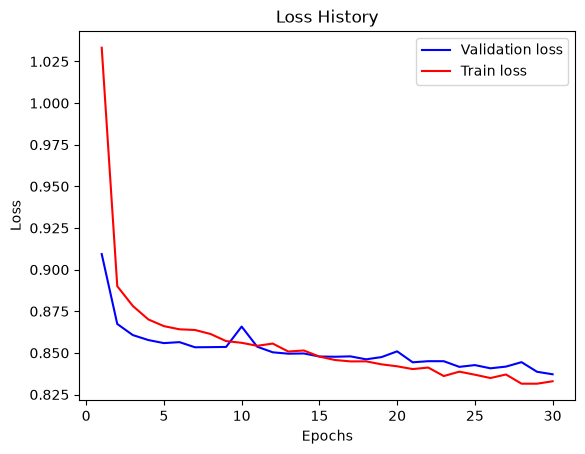

In [ ]:
# 학습 중 epoch에 따라 loss의 변화를 기록하여 나타낸 그래프
plt.plot(range(1, len(history_dict["VLH"])+1), history_dict["VLH"], 'b', label="Validation loss")
plt.plot(range(1, len(history_dict["TLH"])+1), history_dict["TLH"], 'r', label="Train loss")
plt.title("Loss History")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

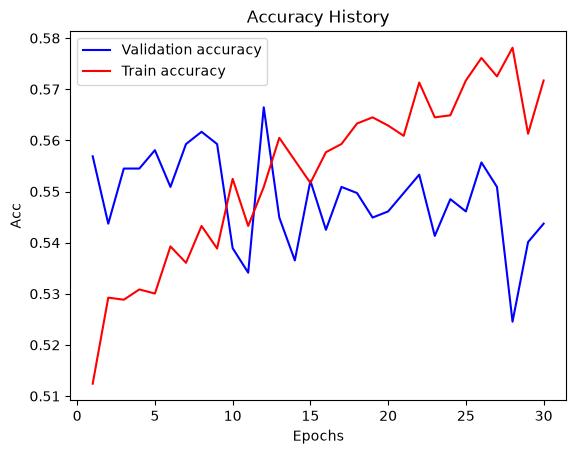

In [ ]:
# 학습 중 epoch에 따라 accuracy의 변화를 기록하여 나타낸 그래프
plt.plot(range(1, len(history_dict["VAH"])+1), history_dict["VAH"], 'b', label="Validation accuracy")
plt.plot(range(1, len(history_dict["TAH"])+1), history_dict["TAH"], 'r', label="Train accuracy")
plt.title("Accuracy History")
plt.xlabel("Epochs")
plt.ylabel("Acc")
plt.legend()
plt.show()

In [ ]:
report = classification_report(
    test_labels, test_preds,
    target_names=le.classes_,
    output_dict=True
)
print(classification_report(test_labels, test_preds, target_names=le.classes_))

              precision    recall  f1-score   support

           F       0.48      0.41      0.44       261
           I       0.72      0.81      0.77       268
           M       0.47      0.48      0.47       306

    accuracy                           0.56       835
   macro avg       0.56      0.57      0.56       835
weighted avg       0.55      0.56      0.56       835



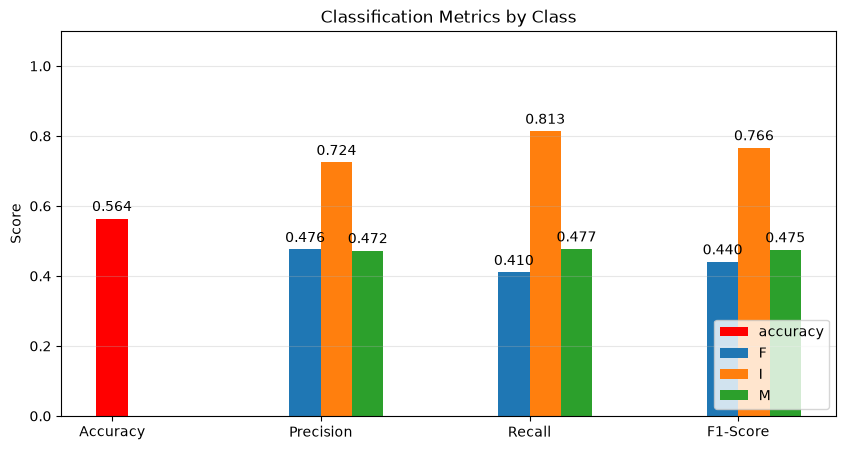

In [ ]:
classes = le.classes_
metrics = ['precision', 'recall', 'f1-score']
accuracy = report['accuracy']

x = np.arange(len(metrics)) + 1
width = 0.15

fig, ax = plt.subplots(figsize=(10,5))

acc_bar = ax.bar(0, accuracy, width, color='r', label='accuracy')
ax.bar_label(acc_bar, fmt='%.3f', padding=3)

for i, cls in enumerate(classes):
    values = [report[cls][m] for m in metrics]
    bars = ax.bar(x + (i - 0.5) * width, values, width, label=cls)
    ax.bar_label(bars, fmt='%.3f', padding=3)

ax.set_xticks(np.arange(len(metrics) + 1), ['Accuracy', 'Precision', 'Recall', 'F1-Score'])
ax.set_ylabel('Score')
ax.set_ylim(0, 1.1)
ax.set_title('Classification Metrics by Class')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)
plt.show()